# Multiclassification with Logistic Regression

W have three main approaches to adapt logistic regression: One-vs-Rest (OvR), One-vs-One (OvO), and multinomial logistic regression.

## Multiclassification approaches

### One-vs-Rest (OvR)

In the OvR approach, a separate classifier is trained for each class, with each classifier distinguishing that class from all other classes combined.
For a problem with three classes (e.g., A, B, and C), three classifiers are created:
- A vs. Not A
- B vs. Not B
- C vs. Not C

**Mathematics:** Each classifier in OvR is trained to maximize the probability of its own class, calculated as:
$$ P(y=i \mid x) = \frac{1}{1 + e^{-(w_i \cdot x + b_i)}} $$

where $w_i$ and $b_i$ are the weight vector and bias for the classifier distinguishing class $i$ from all others.

**Prediction:** For a new data point, each classifier outputs a probability score for its respective class. The final prediction is assigned to the class with the highest probability score among all classifiers.

### One-vs-One (OvO)

OvO trains a separate classifier for each possible pair of classes. For a problem with three classes (A, B, and C), three classifiers are built:
- A vs. B
- B vs. C
- A vs. C

**Mathematics:** Each OvO classifier outputs a probability score for one of its two classes:
$$ P(y=i \mid x) = \frac{1}{1 + e^{-(w_i \cdot x + b_i)}} $$

During prediction, each classifier “votes” for one of its two classes. The final class assigned is the one with the most votes.

**Prediction:** After voting, the class that receives the majority of votes across all classifiers is chosen as the final prediction.

### Multinomial Logistic Regression (Softmax)

Multinomial logistic regression models all classes simultaneously by learning a probability distribution over the classes using a single model.

**Mathematics:** The probability for each class is calculated using the softmax function:
$$ P(y=i \mid x) = \frac{e^{w_i \cdot x + b_i}}{\sum_{j=1}^{k} e^{w_j \cdot x + b_j}} $$

Here, each class $i$ has its own weight vector $w_i$. The model outputs probabilities for each class, summing to 1.

**Prediction:** The class with the highest probability is assigned as the final prediction.

## Comparison of OvR, OvO, and Multinomial Logistic Regression

**Training Complexity:** OvR requires $k$ classifiers, while OvO requires $\frac{k(k-1)}{2}$ classifiers. Multinomial logistic regression needs only one model.

**Model Complexity:** OvR and OvO both simplify the multiclass problem by breaking it into binary problems. OvR is more computationally efficient than OvO. Multinomial logistic regression is efficient during inference and models class probabilities directly.

**Use Cases:** OvR is useful for imbalanced data or when class distinctions are clear; OvO may be helpful for highly separable classes; and multinomial logistic regression is generally preferred when classes are closely related.



**Using PCA to reduce the Iris dataset to two dimensions, we can visualize the decision boundaries created by both OvO and multinomial logistic regression models. This is just for visualization purposes, so don’t worry if you’re not familiar with PCA—we’ll cover it later**

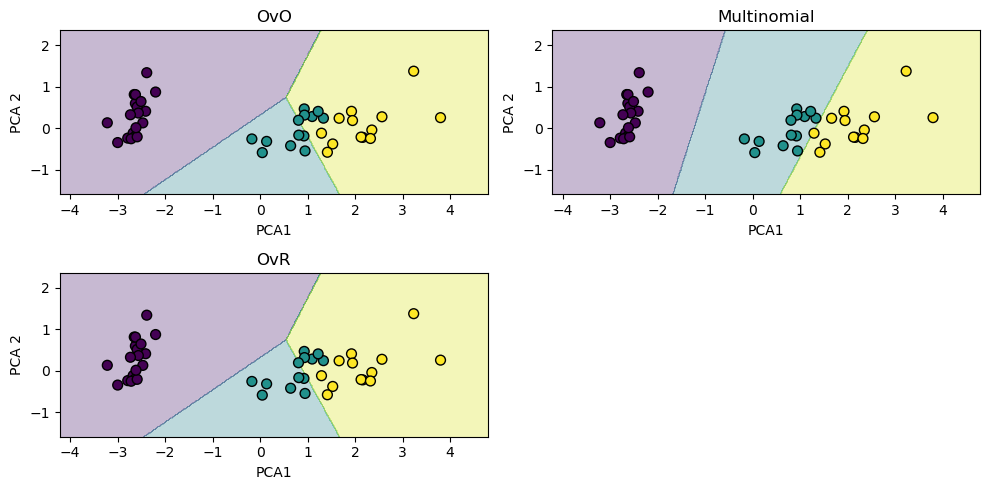

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X, y = iris.data, iris.target
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_reduced, y, test_size=0.3, random_state=42)

ovo_model = LogisticRegression(multi_class='ovr', solver='liblinear')
multinomial_model = LogisticRegression(multi_class='multinomial', solver='lbfgs')
ovo_model.fit(X_train, y_train)
multinomial_model.fit(X_train, y_train)


ovr_model = LogisticRegression(multi_class='ovr', solver='liblinear')
ovr_model.fit(X_train, y_train)



def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', s=50)
    plt.title(title)
    plt.xlabel('PCA1')
    plt.ylabel('PCA 2')

plt.figure(figsize=(10, 5))
plt.subplot(2, 2,1)
plot_decision_boundary(ovo_model, X_test, y_test, 'OvO')
plt.subplot(2,2, 2)
plot_decision_boundary(multinomial_model, X_test, y_test, 'Multinomial')
plt.subplot(2,2,3)
plot_decision_boundary(ovr_model, X_test, y_test, 'OvR')

plt.tight_layout()
plt.show()
